# Formula 1 podium prediction

## 1. Setup

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "f1_clean.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.f1_clean import (
    ASSIGNMENT_LAST_YEAR,
    SENTINEL,
    clean_tables,
    collapse_entries,
    load_raw,
    project_paths,
    raw_hashes,
    replace_sentinels,
)

PATHS = project_paths(ROOT)
PATHS["figures"].mkdir(parents=True, exist_ok=True)
HASHES_AT_START = raw_hashes(PATHS["raw"])

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 40)
pd.set_option("display.width", 120)

NAVY = "#1f4e79"
CLAY = "#c46b2c"
TEAL = "#2f6f6a"


def styled(ax, title, xlabel, ylabel, grid="y"):
    ax.set_title(title, loc="left", fontsize=13, pad=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis=grid, color="#e6e6e6")
    ax.set_axisbelow(True)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(PATHS["figures"] / name, dpi=140, bbox_inches="tight", facecolor="white")
    plt.show()


raw = load_raw(PATHS["raw"])
print(f"Loaded {len(raw)} tables from {PATHS['raw']}")

Loaded 14 tables from C:\Users\Hamdy\f1-podium-prediction\data\raw


## 2. What is in the files

In [2]:
inventory = pd.DataFrame([
    {"table": name, "rows": len(frame), "columns": len(frame.columns)}
    for name, frame in raw.items()
])
display(inventory)

races_raw = replace_sentinels(raw["races"]).copy()
races_raw["year"] = pd.to_numeric(races_raw["year"])
print(
    f"Seasons in races: {int(races_raw['year'].min())}–{int(races_raw['year'].max())}. "
    f"Distinct seasons: {races_raw['year'].nunique()}."
)
print(f"Assignment window named in the brief: 1950–{ASSIGNMENT_LAST_YEAR}.")

,table,rows,columns
0,circuits,78,9
1,constructors,214,5
2,constructor_results,13041,5
3,constructor_standings,13807,7
4,drivers,865,9
5,driver_standings,35718,7
6,races,1172,18
7,results,27590,18
8,qualifying,11320,9
9,lap_times,884145,6


Seasons in races: 1950–2026. Distinct seasons: 77.
Assignment window named in the brief: 1950–2024.


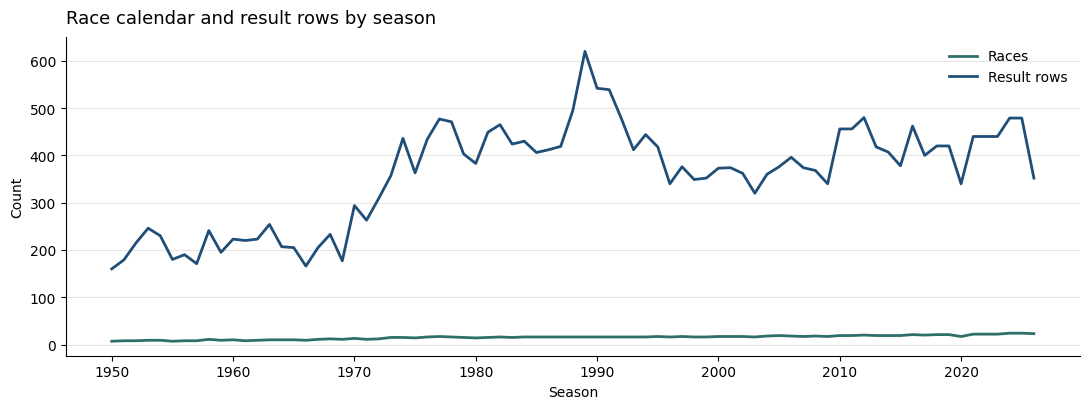

In [3]:
results_year = replace_sentinels(raw["results"])[["raceId"]].merge(
    races_raw[["raceId", "year"]], on="raceId", how="left"
)
volume = pd.DataFrame({
    "races": races_raw.groupby("year").size(),
    "result_rows": results_year.groupby("year").size(),
}).fillna(0)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(volume.index, volume["races"], color=TEAL, linewidth=2, label="Races")
ax.plot(volume.index, volume["result_rows"], color=NAVY, linewidth=2, label="Result rows")
styled(ax, "Race calendar and result rows by season", "Season", "Count")
ax.legend(frameon=False)
save(fig, "01_season_volume.png")

## 3. Sentinel values, before they are converted

,table,column,sentinel_n,rows,sentinel_share
0,constructor_results,status,13024,13041,0.998696
1,races,sprint_time,1145,1172,0.976962
2,races,sprint_date,1142,1172,0.974403
3,drivers,number,802,865,0.927168
4,races,fp3_time,1084,1172,0.924915
5,races,fp2_time,1075,1172,0.917235
6,races,fp3_date,1065,1172,0.908703
7,races,fp1_time,1057,1172,0.901877
8,races,quali_time,1057,1172,0.901877
9,races,fp2_date,1053,1172,0.898464


constructor_results.status raw values:


,rows
status,
\N,13024
D,17


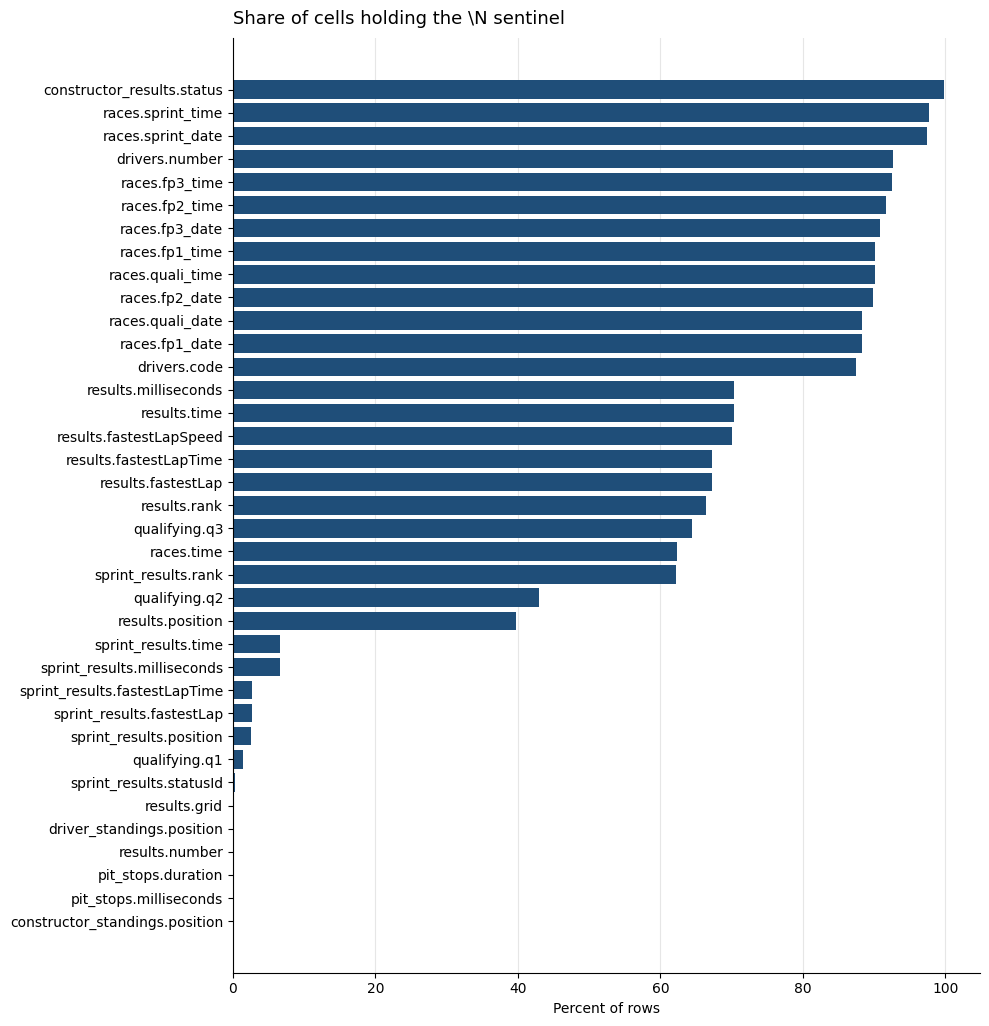

In [4]:
from src.f1_clean import summarize_sentinels

sentinels = summarize_sentinels(raw)
display(sentinels)

status_counts = raw["constructor_results"]["status"].value_counts()
print("constructor_results.status raw values:")
display(status_counts.to_frame("rows"))

plot_df = sentinels.sort_values("sentinel_share")
fig, ax = plt.subplots(figsize=(10, max(6, 0.28 * len(plot_df))))
ax.barh(
    plot_df["table"] + "." + plot_df["column"],
    plot_df["sentinel_share"] * 100,
    color=NAVY,
)
styled(
    ax,
    "Share of cells holding the \\N sentinel",
    "Percent of rows",
    "",
    grid="x",
)
save(fig, "02_sentinel_share.png")

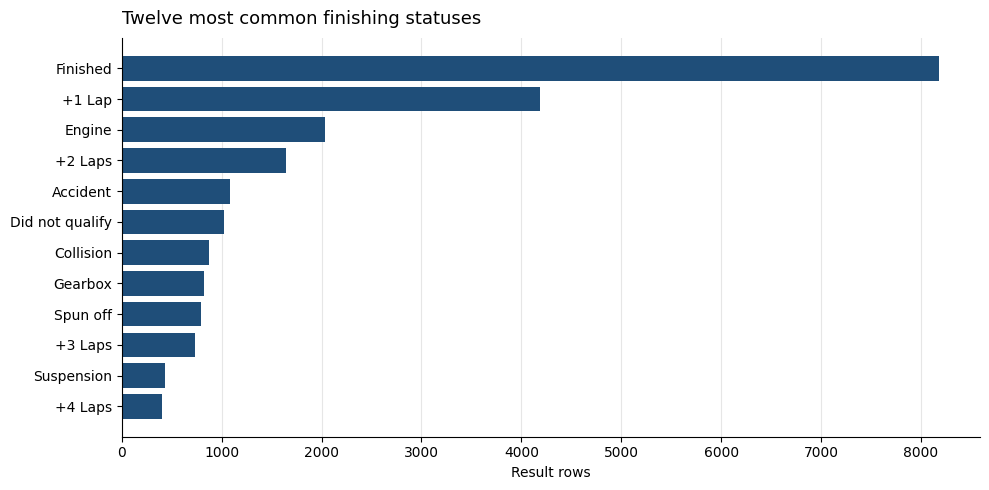

Distinct statuses used in results: 139


In [5]:
results_status = replace_sentinels(raw["results"]).merge(
    replace_sentinels(raw["status"]), on="statusId", how="left"
)
top_status = results_status["status"].value_counts().head(12).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_status.index, top_status.values, color=NAVY)
styled(ax, "Twelve most common finishing statuses", "Result rows", "", grid="x")
save(fig, "03_status_counts.png")
print(f"Distinct statuses used in results: {results_status['status'].nunique()}")

## 4. Keys before cleaning

In [6]:
from src.f1_clean import audit_keys

keys_before = audit_keys(raw)
failed_before = keys_before.loc[~keys_before["passed"]].copy()
print(f"{int(keys_before['passed'].sum())} of {len(keys_before)} checks passed before cleaning.")
display(failed_before)

39 of 42 checks passed before cleaning.


,table,check,columns,rows,null_key_rows,problem_rows,passed
9,lap_times,primary_key,"raceId, driverId, lap",884145,0,1979,False
14,results_driver_race,grain,"raceId, driverId",27590,0,91,False
41,sprint_results,foreign_key,statusId -> status.statusId,590,0,2,False


## 5. Repeated driver-race rows

Repeated result rows: 176
Driver-race pairs involved: 85
Seasons involved: 1950–1978


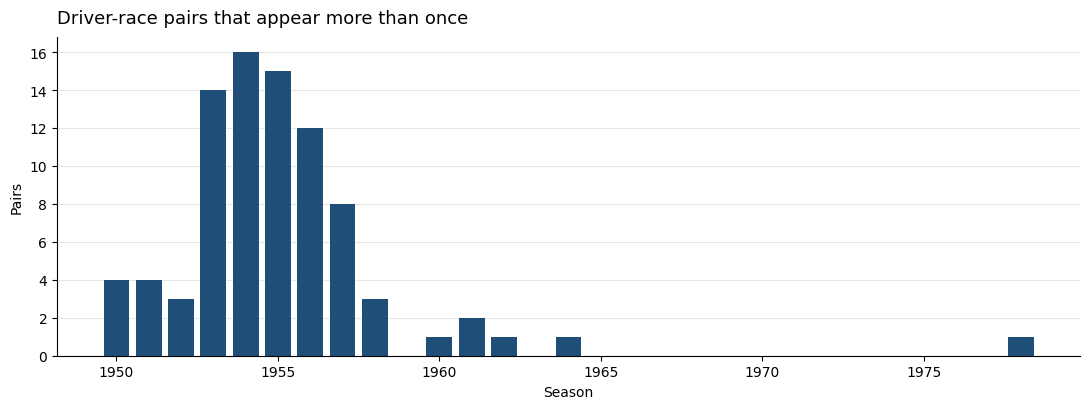

In [7]:
results_view = replace_sentinels(raw["results"]).copy()
for column in ["grid", "positionOrder", "laps", "points"]:
    results_view[column] = pd.to_numeric(results_view[column])

drivers_view = replace_sentinels(raw["drivers"]).copy()
drivers_view["driver"] = drivers_view["forename"] + " " + drivers_view["surname"]

repeated = results_view.loc[results_view.duplicated(["raceId", "driverId"], keep=False)].copy()
repeated = repeated.merge(races_raw[["raceId", "year", "name"]], on="raceId", how="left")
repeated = repeated.merge(drivers_view[["driverId", "driver"]], on="driverId", how="left")
pairs = repeated.drop_duplicates(["raceId", "driverId"])

print(f"Repeated result rows: {len(repeated)}")
print(f"Driver-race pairs involved: {len(pairs)}")
print(f"Seasons involved: {int(pairs['year'].min())}–{int(pairs['year'].max())}")

year_counts = pairs.groupby("year").size().reindex(range(1950, 1979), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(year_counts.index, year_counts.values, color=NAVY, width=0.8)
styled(ax, "Driver-race pairs that appear more than once", "Season", "Pairs")
save(fig, "04_duplicate_pairs_by_year.png")

In [8]:
french_id = races_raw.loc[
    (races_raw["year"] == 1951) & (races_raw["name"] == "French Grand Prix"),
    "raceId",
].iloc[0]
french = repeated.loc[repeated["raceId"] == french_id].copy()
shared_numbers = french.groupby("number")["driverId"].nunique()
shared_numbers = shared_numbers[shared_numbers > 1].index
french_shared = french.loc[french["number"].isin(shared_numbers), [
    "driver", "number", "grid", "positionText", "positionOrder", "laps", "points",
]].sort_values(["number", "positionOrder", "driver"])
display(french_shared)

,driver,number,grid,positionText,positionOrder,laps,points
81,Juan Fangio,24,1.0,11,11,55,0.0
93,Luigi Fagioli,24,1.0,11,11,55,0.0
92,Juan Fangio,8,7.0,1,1,77,5.0
79,Luigi Fagioli,8,7.0,1,1,77,4.0


In [9]:
late = repeated.loc[repeated["year"] >= 1965, [
    "year", "name", "driver", "constructorId", "grid", "positionText", "positionOrder", "laps",
]].sort_values(["year", "driver", "positionOrder"])
print(f"Repeated rows after 1964: {len(late)}")
display(late)

status_view = replace_sentinels(raw["status"])
late_status = repeated.loc[repeated["year"] >= 1965, ["statusId"]].merge(status_view, on="statusId")
print("Statuses on those rows:")
display(late_status["status"].value_counts().to_frame("rows"))

Repeated rows after 1964: 2


,year,name,driver,constructorId,grid,positionText,positionOrder,laps
0,1978,Italian Grand Prix,Harald Ertl,54,0.0,F,26,0
1,1978,Italian Grand Prix,Harald Ertl,57,0.0,F,29,0


Statuses on those rows:


,rows
status,
Did not qualify,1
Did not prequalify,1


## 6. What “podium” means in this file

In [10]:
results_view["brief_podium"] = results_view["positionOrder"] <= 3
results_view["official_podium"] = results_view["positionText"].isin(["1", "2", "3"])
brief_only = results_view["brief_podium"] & ~results_view["official_podium"]
official_only = results_view["official_podium"] & ~results_view["brief_podium"]
print(f"Brief podium rows: {int(results_view['brief_podium'].sum())}")
print(f"Official podium rows: {int(results_view['official_podium'].sum())}")
print(f"In the brief label only: {int(brief_only.sum())}")
print(f"In the official label only: {int(official_only.sum())}")

conflict_ids = results_view.loc[brief_only, "raceId"].unique()
conflict_race = results_view.loc[results_view["raceId"].isin(conflict_ids)].copy()
conflict_race = conflict_race.merge(drivers_view[["driverId", "driver"]], on="driverId", how="left")
conflict_race = conflict_race.merge(races_raw[["raceId", "year", "name"]], on="raceId", how="left")
conflict_race = conflict_race.merge(status_view, on="statusId", how="left")
show_cols = ["year", "name", "driver", "grid", "positionText", "positionOrder", "points", "status"]
display(
    conflict_race.sort_values(["raceId", "positionOrder"])[show_cols]
    .head(8)
)

Brief podium rows: 3517
Official podium rows: 3516
In the brief label only: 1
In the official label only: 0


,year,name,driver,grid,positionText,positionOrder,points,status
0,1983,Brazilian Grand Prix,Nelson Piquet,4.0,1,1,9.0,Finished
1,1983,Brazilian Grand Prix,Niki Lauda,9.0,3,2,4.0,Finished
2,1983,Brazilian Grand Prix,Jacques Laffite,18.0,4,3,3.0,Finished
3,1983,Brazilian Grand Prix,Patrick Tambay,3.0,5,4,2.0,Finished
4,1983,Brazilian Grand Prix,Marc Surer,20.0,6,5,1.0,Finished
5,1983,Brazilian Grand Prix,Alain Prost,2.0,7,6,0.0,+1 Lap
6,1983,Brazilian Grand Prix,Derek Warwick,5.0,8,7,0.0,+1 Lap
7,1983,Brazilian Grand Prix,Chico Serra,23.0,9,8,0.0,+1 Lap


## 7. Coverage the later feature work has to respect

Scheduled races with no result rows: 7


,year,round,name,date
1165,2026,17,Singapore Grand Prix,2026-10-11
1166,2026,18,United States Grand Prix,2026-10-25
1167,2026,19,Mexico City Grand Prix,2026-11-01
1168,2026,20,Brazilian Grand Prix,2026-11-08
1169,2026,21,Las Vegas Grand Prix,2026-11-22
1170,2026,22,Qatar Grand Prix,2026-11-29
1171,2026,23,Abu Dhabi Grand Prix,2026-12-06


First season present in qualifying: 1994


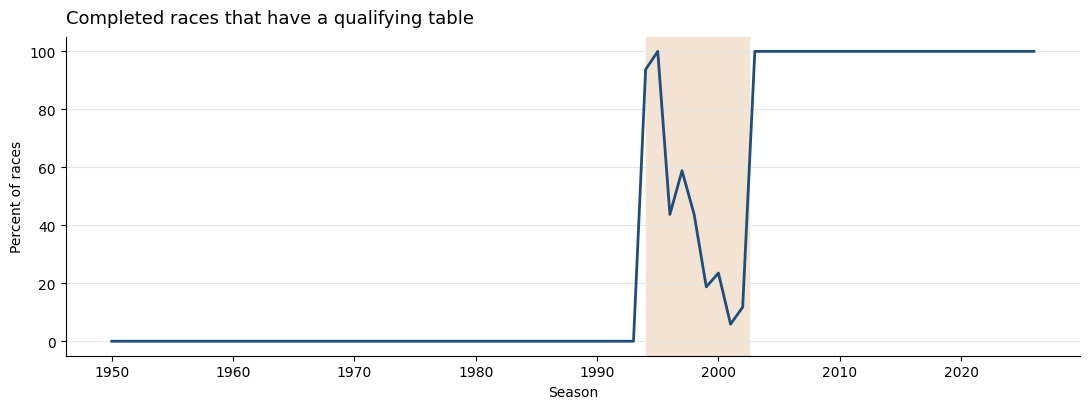

In [11]:
result_race_ids = set(results_view["raceId"])
unraced = races_raw.loc[~races_raw["raceId"].isin(result_race_ids), ["year", "round", "name", "date"]]
unraced = unraced.sort_values(["year", "round"])
print(f"Scheduled races with no result rows: {len(unraced)}")
display(unraced)

quali_ids = set(replace_sentinels(raw["qualifying"])["raceId"])
completed = races_raw.loc[races_raw["raceId"].isin(result_race_ids)].copy()
completed["has_qualifying"] = completed["raceId"].isin(quali_ids)
coverage = completed.groupby("year")["has_qualifying"].mean()
print(f"First season present in qualifying: {int(coverage[coverage > 0].index.min())}")

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(coverage.index, coverage.values * 100, color=NAVY, linewidth=2)
ax.axvspan(1994, 2002.5, color="#f3e3d3", zorder=0)
styled(ax, "Completed races that have a qualifying table", "Season", "Percent of races")
ax.set_ylim(-5, 105)
save(fig, "05_qualifying_coverage.png")

Rows with a null grid, by race:


,year,name,date,null_grid_rows
0,2025,Qatar Grand Prix,2025-11-30,20
1,2026,Azerbaijan Grand Prix,2026-09-26,22


Rows with grid 0: 1638


,drivers,code_missing,number_missing
decade,,,
1950,332,99.7,100.0
1960,145,100.0,100.0
1970,135,100.0,100.0
1980,79,100.0,100.0
1990,66,81.8,100.0
2000,49,26.5,77.6
2010,41,0.0,17.1
2020,18,0.0,0.0


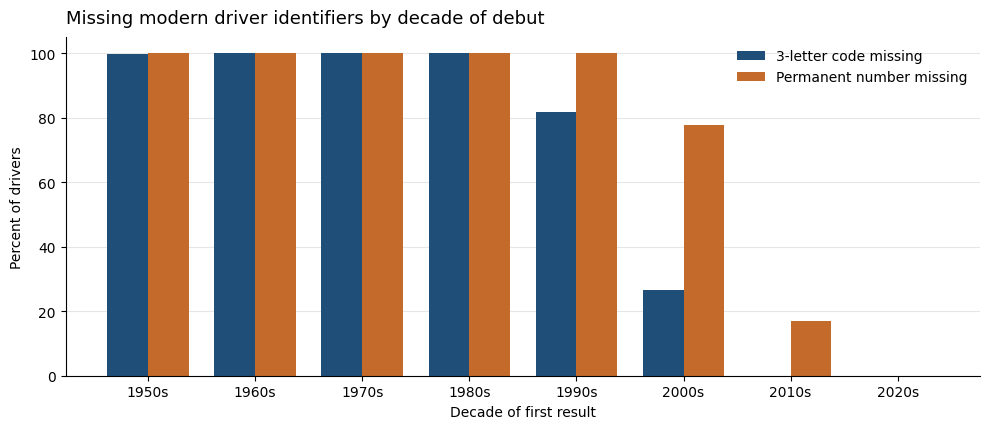

In [12]:
grid_null = results_view.loc[results_view["grid"].isna(), ["raceId"]].merge(
    races_raw[["raceId", "year", "name", "date"]], on="raceId"
)
print("Rows with a null grid, by race:")
display(grid_null.groupby(["year", "name", "date"]).size().rename("null_grid_rows").reset_index())
print(f"Rows with grid 0: {int((results_view['grid'] == 0).sum())}")

debut = results_view.merge(races_raw[["raceId", "year"]], on="raceId").groupby("driverId")["year"].min()
driver_codes = drivers_view.merge(debut.rename("debut"), left_on="driverId", right_index=True, how="inner")
driver_codes["decade"] = (driver_codes["debut"] // 10 * 10).astype(int)
driver_codes["code_missing"] = driver_codes["code"].isna()
driver_codes["number_missing"] = driver_codes["number"].isna()
code_by_decade = driver_codes.groupby("decade").agg(
    drivers=("driverId", "size"),
    code_missing=("code_missing", "mean"),
    number_missing=("number_missing", "mean"),
)
code_by_decade[["code_missing", "number_missing"]] = code_by_decade[["code_missing", "number_missing"]] * 100
display(code_by_decade.round(1))

fig, ax = plt.subplots(figsize=(10, 4.4))
x = np.arange(len(code_by_decade))
width = 0.38
ax.bar(x - width / 2, code_by_decade["code_missing"], width=width, color=NAVY, label="3-letter code missing")
ax.bar(x + width / 2, code_by_decade["number_missing"], width=width, color=CLAY, label="Permanent number missing")
styled(ax, "Missing modern driver identifiers by decade of debut", "Decade of first result", "Percent of drivers")
ax.set_xticks(x, [str(int(year)) + "s" for year in code_by_decade.index], rotation=0)
ax.set_ylim(0, 105)
ax.legend(frameon=False)
save(fig, "06_driver_identifier_missingness.png")

In [13]:
standings = replace_sentinels(raw["driver_standings"]).copy()
standings["points"] = pd.to_numeric(standings["points"])
unranked = standings.loc[standings["position"].isna()].merge(
    races_raw[["raceId", "year", "name"]], on="raceId"
)
print(f"Driver-standings rows with no position: {len(unranked)}")
display(
    unranked.groupby(["year", "name", "positionText"])
    .size()
    .rename("rows")
    .reset_index()
)

Driver-standings rows with no position: 13


,year,name,positionText,rows
0,2025,Australian Grand Prix,-,6
1,2025,Chinese Grand Prix,-,1
2,2026,Australian Grand Prix,-,6


## 8. The cleaning rules

In [14]:
result = clean_tables(raw)

print("Coercion failures (empty means every present value cast successfully):")
display(result.coercion_failures)

print("Parsed strings against the millisecond columns already in the file:")
display(result.time_checks)

print(f"Disqualified constructor results: {int(result.cleaned['constructor_results']['disqualified'].sum())}")

print("Missing-value method for every column that had a blank marker:")
display(result.missing_policy)
left_blank = result.missing_policy.loc[result.missing_policy["method"] == "leave missing", "values_filled"]
assert left_blank.eq(0).all()

Coercion failures (empty means every present value cast successfully):


,table,column,failed_n


Parsed strings against the millisecond columns already in the file:


,check,rows,max_abs_seconds
0,results winner time vs milliseconds,1167,0.000000e+00
1,lap time string vs milliseconds,882166,1.000000e-03
2,pit duration string vs milliseconds,22774,2.273737e-13


Disqualified constructor results: 17
Missing-value method for every column that had a blank marker:


,table,column,blank_markers,method,values_filled,still_missing,reason
0,constructor_results,disqualified,13024,filled with False,13024,0,Each \N in status was written here as False. E...
1,constructor_results,status,13024,code as not disqualified,0,13024,\N means the constructor was not disqualified....
2,constructor_standings,position,1,leave missing,0,1,One standings row is unranked. A median rank w...
3,driver_standings,position,13,leave missing,0,13,The text is already '-': unranked. The mode wo...
4,drivers,code,757,leave missing,0,757,Three-letter codes did not exist for most of t...
5,drivers,number,802,leave missing,0,802,Permanent numbers did not exist for most of th...
6,pit_stops,duration,3,leave missing,0,3,Three stops have no duration. A median would h...
7,pit_stops,milliseconds,3,leave missing,0,3,The same three stops have no duration in milli...
8,qualifying,q1,164,leave missing,0,164,The driver set no Q1 time. A median lap time w...
9,qualifying,q2,4867,leave missing,0,4867,The driver did not reach Q2. A median would sa...


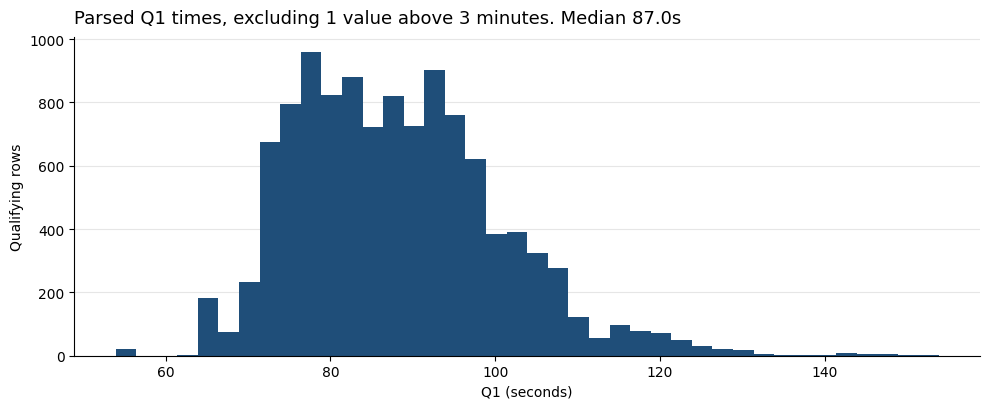

Qualifying times longer than 3 minutes, left as parsed from the source string:


,year,name,forename,surname,q1,q1_seconds
0,1995,Japanese Grand Prix,Mark,Blundell,16:42.640,1002.64


,time,winner_time_seconds,gap_seconds,elapsed_seconds
0,1:34:50.616,5690.616,NaN,5690.616
1,+5.478,NaN,5.478,5696.094
2,+8.163,NaN,8.163,5698.779
3,+17.181,NaN,17.181,5707.797
4,+18.014,NaN,18.014,5708.63
22,1:31:18.555,5478.555,NaN,5478.555


In [15]:
q1 = result.cleaned["qualifying"][["raceId", "driverId", "q1", "q1_seconds"]].dropna(subset=["q1_seconds"])
ordinary = q1.loc[q1["q1_seconds"] <= 180, "q1_seconds"]
odd = q1.loc[q1["q1_seconds"] > 180].merge(
    result.cleaned["races"][["raceId", "year", "name"]], on="raceId"
).merge(
    result.cleaned["drivers"][["driverId", "forename", "surname"]], on="driverId"
)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.hist(ordinary, bins=40, color=NAVY)
styled(
    ax,
    f"Parsed Q1 times, excluding {len(odd)} value above 3 minutes. Median {ordinary.median():.1f}s",
    "Q1 (seconds)",
    "Qualifying rows",
)
save(fig, "07_q1_seconds.png")
print("Qualifying times longer than 3 minutes, left as parsed from the source string:")
display(odd[["year", "name", "forename", "surname", "q1", "q1_seconds"]])

sample_times = result.cleaned["results"].loc[
    result.cleaned["results"]["winner_time_seconds"].notna()
    | result.cleaned["results"]["gap_seconds"].notna(),
    ["time", "winner_time_seconds", "gap_seconds", "elapsed_seconds"],
].head(6)
display(sample_times)

In [16]:
keys_after = result.keys_after
failed_after = keys_after.loc[~keys_after["passed"]].copy()
print(f"{int(keys_after['passed'].sum())} of {len(keys_after)} checks passed after cleaning.")
display(failed_after)
print("Lap-time key repair:")
display(result.lap_conflict_summary)

42 of 43 checks passed after cleaning.


,table,check,columns,rows,null_key_rows,problem_rows,passed
14,results_driver_race,grain,"raceId, driverId",27590,0,91,False


Lap-time key repair:


,kind,groups
0,unique_already,880187
1,exact_duplicate,1710
2,one_millisecond,243
3,larger_conflict,26


## 9. Which row is kept

In [17]:
comparison = result.rule_comparison
print(f"Repeated pairs compared: {len(comparison)}")
print(f"Same resultId: {int(comparison['same_row'].sum())}")
print(f"Same positionOrder: {int(comparison['same_position'].sum())}")
print(f"Same podium label: {int(comparison['same_podium'].sum())}")
print(f"Disagreements: {int((~comparison['same_row']).sum())}")

toy = pd.DataFrame([
    {"raceId": 1, "driverId": 7, "resultId": 10, "positionOrder": 8, "laps": 70},
    {"raceId": 1, "driverId": 7, "resultId": 11, "positionOrder": 2, "laps": 12},
])
toy_compare = pd.DataFrame({
    "rule": ["best_classification", "most_laps"],
    "kept_resultId": [
        int(collapse_entries(toy, "best_classification").iloc[0]["resultId"]),
        int(collapse_entries(toy, "most_laps").iloc[0]["resultId"]),
    ],
})
display(toy)
display(toy_compare)

Repeated pairs compared: 85
Same resultId: 85
Same positionOrder: 85
Same podium label: 85
Disagreements: 0


,raceId,driverId,resultId,positionOrder,laps
0,1,7,10,8,70
1,1,7,11,2,12


,rule,kept_resultId
0,best_classification,11
1,most_laps,10


## 10. The driver-race table, and what cleaning changed

Result rows: 27590
Driver-race rows: 27499
Rows removed by the collapse: 91
Unique (raceId, driverId): True
Shared entries: 85
Shared entries with more than one constructor: 16
Podium definition conflicts: 1
Rows inside the brief's 1950–2024 window: 26668 of 27499


,before,after,median_starters
decade,,,
1950,13.60,14.1,21.0
1960,14.25,14.28,20.0
1970,11.35,11.35,26.0
1980,10.39,10.39,28.0
1990,11.44,11.44,26.0
2000,14.33,14.33,20.0
2010,13.82,13.82,22.0
2020,14.85,14.85,20.0


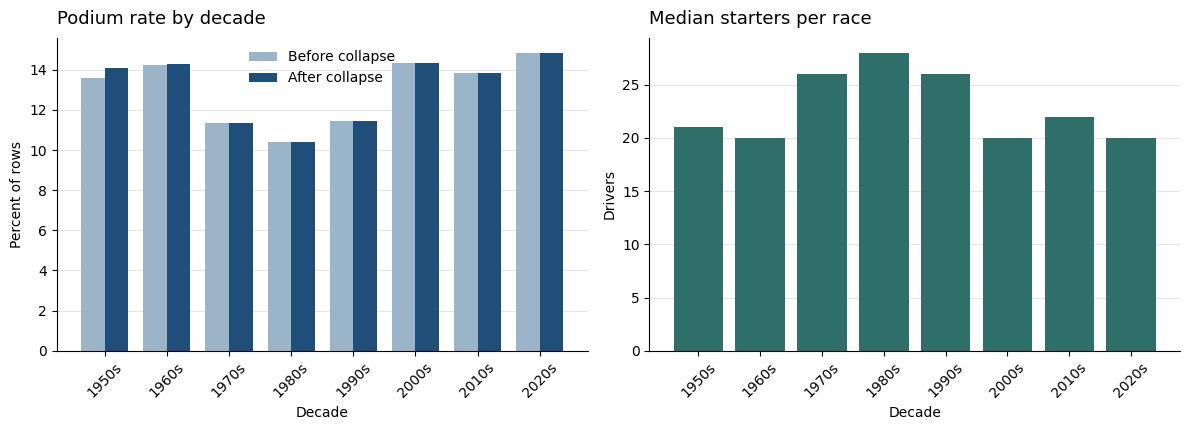

In [18]:
driver_race = result.driver_race
print(f"Result rows: {len(result.cleaned['results'])}")
print(f"Driver-race rows: {len(driver_race)}")
print(f"Rows removed by the collapse: {len(result.cleaned['results']) - len(driver_race)}")
print(f"Unique (raceId, driverId): {not driver_race.duplicated(['raceId', 'driverId']).any()}")
print(f"Shared entries: {int(driver_race['shared_entry'].sum())}")
print(f"Shared entries with more than one constructor: {int((driver_race['n_constructors'] > 1).sum())}")
print(f"Podium definition conflicts: {int(driver_race['podium_definition_conflict'].sum())}")
print(
    f"Rows inside the brief's 1950–{ASSIGNMENT_LAST_YEAR} window: "
    f"{int(driver_race['in_assignment_window'].sum())} of {len(driver_race)}"
)

before = results_view[["raceId", "positionOrder"]].merge(
    races_raw[["raceId", "year"]], on="raceId", how="left"
)
before["podium"] = before["positionOrder"] <= 3
before["decade"] = (before["year"] // 10 * 10).astype(int)
after = driver_race[["raceId", "year", "podium"]].copy()
after["decade"] = (after["year"] // 10 * 10).astype(int)

rate = pd.DataFrame({
    "before": before.groupby("decade")["podium"].mean() * 100,
    "after": after.groupby("decade")["podium"].mean() * 100,
})
field = (
    after.groupby(["decade", "raceId"]).size()
    .groupby("decade").median()
    .rename("median_starters")
)
display(rate.round(2).join(field))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
x = np.arange(len(rate))
width = 0.38
axes[0].bar(x - width / 2, rate["before"], width=width, color="#9bb4c8", label="Before collapse")
axes[0].bar(x + width / 2, rate["after"], width=width, color=NAVY, label="After collapse")
styled(axes[0], "Podium rate by decade", "Decade", "Percent of rows")
axes[0].set_xticks(x, [str(int(year)) + "s" for year in rate.index], rotation=45)
axes[0].legend(frameon=False)

axes[1].bar(x, field.values, color=TEAL)
styled(axes[1], "Median starters per race", "Decade", "Drivers")
axes[1].set_xticks(x, [str(int(year)) + "s" for year in field.index], rotation=45)
save(fig, "08_podium_rate_before_after.png")

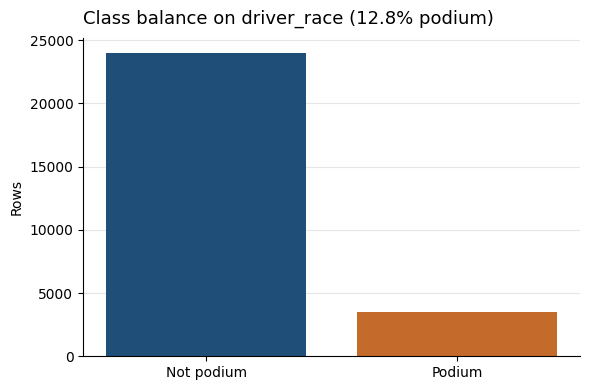

Races by how many drivers carry the podium label:


,races
podium,
3,1147
4,16
5,2


In [19]:
balance = driver_race["podium"].value_counts().rename({False: "Not podium", True: "Podium"})
balance_share = driver_race["podium"].mean()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(balance.index, balance.values, color=[NAVY, CLAY])
styled(ax, f"Class balance on driver_race ({balance_share * 100:.1f}% podium)", "", "Rows")
save(fig, "09_class_balance.png")

multi_podium = driver_race.groupby("raceId")["podium"].sum()
print("Races by how many drivers carry the podium label:")
display(multi_podium.value_counts().sort_index().rename("races").to_frame())

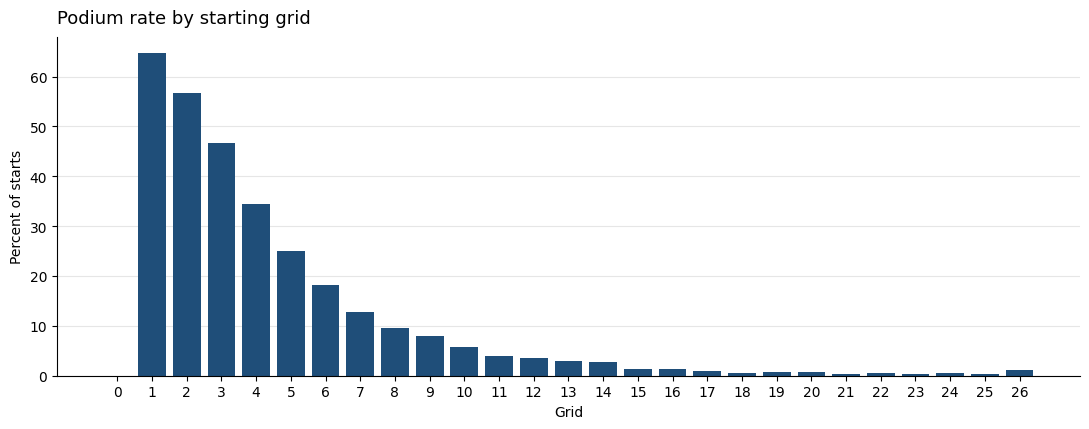

Grid 0 podium rate: 0.0% on 1635 starts
Starts on grids with fewer than 50 starts, omitted from the chart: 163
Starts with a null grid, also omitted: 42


In [20]:
grid = driver_race.dropna(subset=["grid"]).copy()
grid["grid"] = grid["grid"].astype(int)
grid_rates = grid.groupby("grid")["podium"].agg(rate="mean", starts="size")
plotted = grid_rates.loc[grid_rates["starts"] >= 50].copy()
omitted = int(grid_rates.loc[grid_rates["starts"] < 50, "starts"].sum())

fig, ax = plt.subplots(figsize=(11, 4.4))
colors = [CLAY if grid_pos == 0 else NAVY for grid_pos in plotted.index]
ax.bar(plotted.index.astype(str), plotted["rate"] * 100, color=colors)
styled(ax, "Podium rate by starting grid", "Grid", "Percent of starts")
save(fig, "10_podium_rate_by_grid.png")
grid_zero = driver_race.loc[driver_race["grid"] == 0, "podium"]
print(f"Grid 0 podium rate: {grid_zero.mean():.1%} on {len(grid_zero)} starts")
print(f"Starts on grids with fewer than 50 starts, omitted from the chart: {omitted}")
print(f"Starts with a null grid, also omitted: {int(driver_race['grid'].isna().sum())}")

## 11. Handoff

In [21]:
from src.f1_clean import DRIVER_RACE_DICTIONARY, save_outputs

dictionary = pd.DataFrame(DRIVER_RACE_DICTIONARY, columns=["column", "role", "meaning"])
display(dictionary)

kept_example = result.duplicate_rows.loc[result.duplicate_rows["raceId"] == int(french_id)].copy()
name_map = (
    drivers_view.assign(driverId=pd.to_numeric(drivers_view["driverId"]))
    .set_index("driverId")["driver"]
)
kept_example["driver"] = kept_example["driverId"].map(name_map)
shared_number_ids = pd.to_numeric(pd.Index(shared_numbers))
display(
    kept_example.loc[kept_example["number"].isin(shared_number_ids), [
        "driver", "number", "grid", "positionText", "positionOrder", "laps", "kept",
    ]].sort_values(["number", "positionOrder", "driver"])
)

assert result.coercion_failures.empty
time_gap = result.time_checks.loc[~(result.time_checks["max_abs_seconds"] < 0.01)]
if time_gap.empty:
    print("Parsed times match the millisecond columns within 0.01 seconds.")
else:
    print("These source columns disagree with the millisecond values by 0.01 seconds or more. Both numbers are kept:")
    display(time_gap)
assert not driver_race.duplicated(["raceId", "driverId"]).any()
assert not result.cleaned["lap_times"].duplicated(["raceId", "driverId", "lap"]).any()
assert HASHES_AT_START == raw_hashes(PATHS["raw"])

save_outputs(result, PATHS)
print("Wrote cleaned tables, driver_race, and audit files.")
print(f"Raw files unchanged: {HASHES_AT_START == raw_hashes(PATHS['raw'])}")

,column,role,meaning
0,raceId,identifier,Race key. Already known when the race is sched...
1,driverId,identifier,Driver key.
2,resultId,identifier,resultId of the row kept by the collapse rule.
3,year,pre_race_context,Season. Known before the race.
4,round,pre_race_context,Round number. Known before the race.
5,race_date,pre_race_context,Scheduled race date.
6,circuitId,pre_race_context,Circuit. Known before the race.
7,race_name,pre_race_context,Grand Prix name.
8,constructorId,pre_race_context,Constructor on the kept row. When n_constructo...
9,car_number,pre_race_context,Car number on the kept row.


,driver,number,grid,positionText,positionOrder,laps,kept
20185,Juan Fangio,8,7,1,1,77,True
19917,Luigi Fagioli,8,7,1,1,77,True
19927,Juan Fangio,24,1,11,11,55,False
20187,Luigi Fagioli,24,1,11,11,55,False


Wrote cleaned tables, driver_race, and audit files.
Raw files unchanged: True


## 12. Features that exist before the race

,column,group,meaning
0,grid,grid,Starting grid after penalties. Known before th...
1,front_row,grid,"1 when the grid is 1 or 2, otherwise 0. Missin..."
2,quali_position,qualifying,Official qualifying position for this race. Kn...
3,reached_q3,qualifying,1 when the driver set a Q3 time. Missing for a...
4,quali_position_missing,qualifying,"1 when quali_position is missing, so an impute..."
5,driver_podium_rate_last5,form,Share of this driver's previous 5 starts that ...
6,driver_points_last5,form,Points from this driver's previous 5 starts. T...
7,constructor_podium_rate_last5,form,Mean podium share of this constructor's cars o...
8,career_starts,form,Number of race starts this driver had before t...
9,form_missing,form,"1 on a driver's first start in the file, when ..."


Rows in the modeling window: 8970
split
train         6411
test          1359
validation    1200
grid


,grid,starts,podium_rate
0,1,300,0.793333
1,2,299,0.622074
2,3,300,0.500000
3,4,300,0.313333
4,5,300,0.216667
5,6,300,0.160000
6,7,300,0.103333
7,8,300,0.053333
8,9,300,0.043333
9,10,299,0.046823


qualifying


,quali_position,starts,podium_rate
0,1,300,0.780000
1,2,300,0.623333
2,3,300,0.490000
3,4,300,0.316667
4,5,300,0.253333
5,6,300,0.166667
6,7,300,0.096667
7,8,300,0.046667
8,9,300,0.043333
9,10,300,0.040000


standings


,standing_bin,starts,podium_rate
0,1,284,0.665493
1,2-3,567,0.492063
2,4-10,1952,0.171107
3,11+,3134,0.014040


form


,form_bin,starts,podium_rate
0,0,4344,0.030157
1,0-20%,763,0.197903
2,20-40%,474,0.394515
3,40%+,758,0.565963


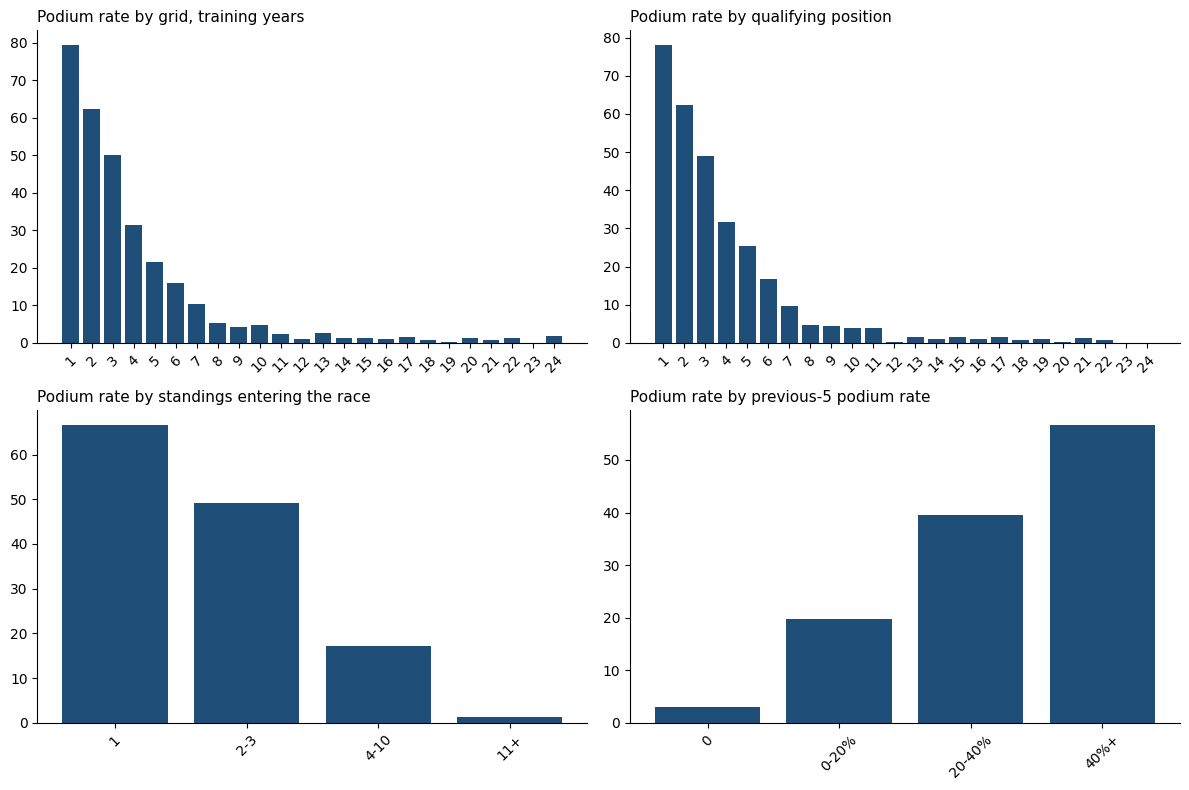

Wrote model_frame.csv


In [22]:
from src.f1_features import (
    FEATURE_COLUMNS,
    LEAKAGE_COLUMNS,
    build_model_frame,
    feature_dictionary_frame,
    feature_evidence,
    modeling_sample,
)
from src.f1_questions import plot_feature_evidence

model = build_model_frame(result.driver_race, result.cleaned)
sample = modeling_sample(model)
display(feature_dictionary_frame())
print("Rows in the modeling window:", len(sample))
print(sample["split"].value_counts().to_string())
assert not any(column in model.columns for column in LEAKAGE_COLUMNS)
assert not sample.duplicated(["raceId", "driverId"]).any()

evidence = feature_evidence(model)
for name, table in evidence.items():
    print(name)
    display(table)
save(plot_feature_evidence(evidence), "11_feature_evidence.png")
model.to_csv(PATHS["processed"] / "model_frame.csv", index=False)
feature_dictionary_frame().to_csv(PATHS["processed"] / "model_feature_dictionary.csv", index=False)
print("Wrote model_frame.csv")

## 13. Which circuits convert a front-row start into a podium?

Using the starting grid, the highest front-row conversion before 2014 is Circuit de Nevers Magny-Cours at 80.6% (29 podiums from 36 front-row starts). From 2014 onward it is Yas Marina Circuit at 86.4% (19 from 22). Circuits need at least 20 front-row starts in an era, so a handful of races cannot top the list. Among circuits that clear that bar in both eras, Circuit de Monaco gains the most ranks (23 to 2), and Hungaroring loses the most (4 to 10). Qualifying position is not the same list. In 2003-2024, 38 drivers qualified on the front row and started further back. They podium 28.9% of the time, against 72.6% for the 818 who qualified on the front row and started there. A penalty is why those two columns come apart, so the ranking above uses the grid.


,circuit_name,country,front_row_starts,podiums,podium_rate,era,rank
0,Circuit de Nevers Magny-Cours,France,36,29,0.805556,1950-2013,1
1,Sepang International Circuit,Malaysia,30,21,0.700000,1950-2013,2
2,Suzuka Circuit,Japan,50,35,0.700000,1950-2013,2
3,Hungaroring,Hungary,56,38,0.678571,1950-2013,4
4,Autódromo do Estoril,Portugal,26,17,0.653846,1950-2013,5
5,Circuit de Barcelona-Catalunya,Spain,46,30,0.652174,1950-2013,6
6,Shanghai International Circuit,China,20,13,0.650000,1950-2013,7
7,Hockenheimring,Germany,66,40,0.606061,1950-2013,8


,circuit_name,country,front_row_starts,podiums,podium_rate,era,rank
0,Yas Marina Circuit,UAE,22,19,0.863636,2014-2024,1
1,Circuit de Monaco,Monaco,20,17,0.850000,2014-2024,2
2,Circuit de Barcelona-Catalunya,Spain,22,18,0.818182,2014-2024,3
3,Circuit de Spa-Francorchamps,Belgium,22,18,0.818182,2014-2024,3
4,Circuit of the Americas,USA,20,16,0.800000,2014-2024,5
5,Silverstone Circuit,UK,24,18,0.750000,2014-2024,6
6,Red Bull Ring,Austria,26,19,0.730769,2014-2024,7
7,Autodromo Nazionale di Monza,Italy,22,16,0.727273,2014-2024,8


,circuit_name,country,podium_rate_pre,rank_pre,front_row_starts_pre,podium_rate_post,rank_post,front_row_starts_post,ranks_gained
0,Circuit de Monaco,Monaco,0.491667,23,120,0.850000,2,20,21
1,Autodromo Nazionale di Monza,Italy,0.483871,25,124,0.727273,8,22,17
2,Circuit de Spa-Francorchamps,Belgium,0.550562,17,89,0.818182,3,22,14
3,Red Bull Ring,Austria,0.520000,20,50,0.730769,7,26,13
4,Silverstone Circuit,UK,0.563830,14,94,0.750000,6,24,8
5,Circuit de Barcelona-Catalunya,Spain,0.652174,6,46,0.818182,3,22,3
6,Hungaroring,Hungary,0.678571,4,56,0.590909,10,22,-6


,group,starts,podium_rate
0,Qualified front row and started there,818,0.726161
1,Qualified front row but started further back,38,0.289474


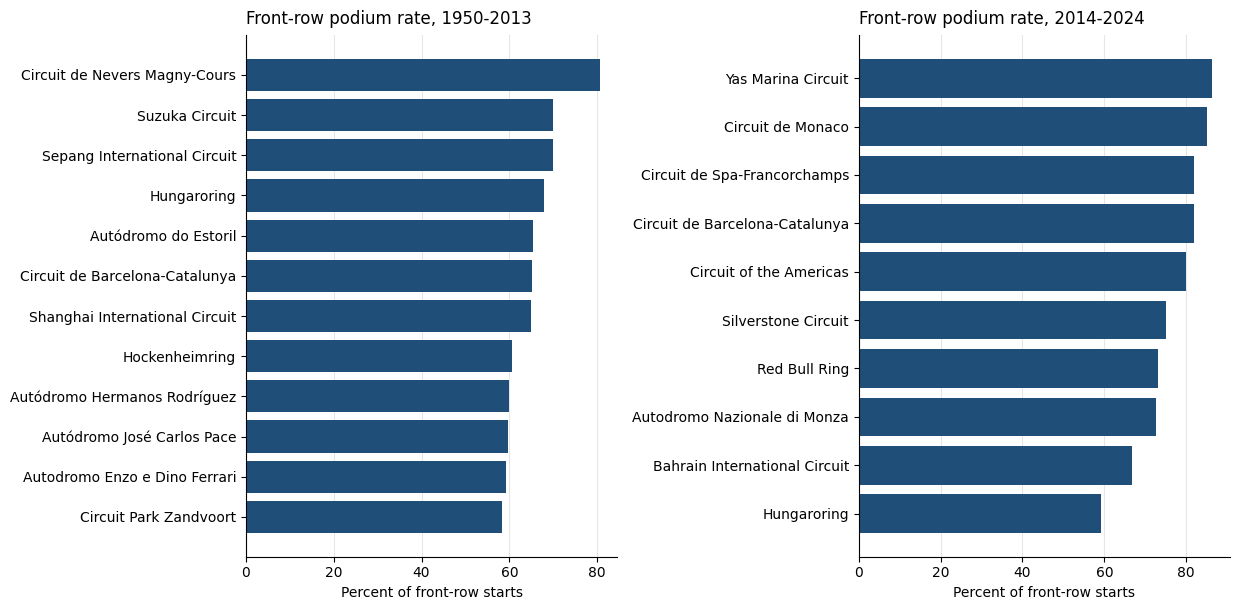

In [23]:
from src.f1_questions import (
    front_row_conversion,
    home_advantage,
    mechanical_retirements,
    narrate_front_row,
    narrate_home,
    narrate_mechanical,
    plot_front_row,
    plot_home,
    plot_mechanical,
    status_audit,
)

ranked = front_row_conversion(result.driver_race, result.cleaned["circuits"], result.cleaned["qualifying"])
print(narrate_front_row(ranked))
display(ranked["pre_2014"].head(8))
display(ranked["from_2014"].head(8))
display(ranked["rank_change"].head(8))
display(ranked["qualifying_versus_grid"])
save(plot_front_row(ranked), "12_front_row_conversion.png")

## 14. Do drivers podium more often at home once the start slot is held fixed?

The comparison holds the starting position roughly fixed, so a home driver who also qualified at the front is not the whole result. grid 1: home 57.6% (92 starts), away 64.7% (1032 starts), gap -7.1 points | grid 2-3: home 53.5% (172 starts), away 51.0% (2074 starts), gap +2.5 points | grid 4-10: home 15.1% (649 starts), away 16.6% (7231 starts), gap -1.5 points | grid 11+: home 1.6% (1411 starts), away 1.7% (12372 starts), gap -0.0 points. Blank grids and grid 0 are left out, because those rows have no starting slot to control for. East German nationality is matched to German circuits, and a dual national is at home in either country. This is a difference inside a grid band, not a claim that the crowd causes the result.


,grid_band,where,starts,podium_rate
0,1,away,1032,0.647287
1,1,home,92,0.576087
2,2-3,away,2074,0.509643
3,2-3,home,172,0.534884
4,4-10,away,7231,0.165537
5,4-10,home,649,0.151002
6,11+,away,12372,0.016731
7,11+,home,1411,0.016300


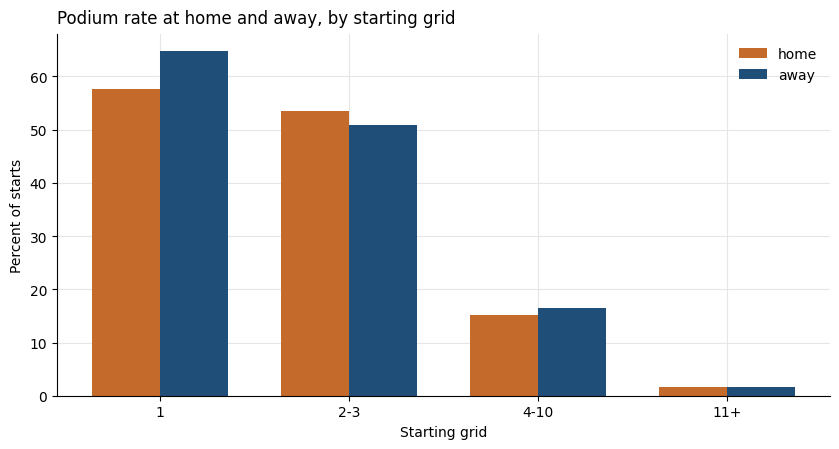

In [24]:
home = home_advantage(result.driver_race, result.cleaned["drivers"], result.cleaned["circuits"])
print(narrate_home(home))
display(home)
save(plot_home(home), "13_home_by_grid.png")

## 15. Which constructors retire for mechanical reasons?

category
mechanical        76
classified        34
not_attributed    10
crash              7
driver             7
did_not_start      4
regulation         3
A mechanical retirement is a start whose status names a failed component. Crashes, driver causes, regulation decisions, and unclassified 'Retired' rows are not counted. Cars that did not start are out of the denominator. Constructors with fewer than 30 starts in an era are left out of that era, and the comparison below keeps constructors that clear the bar in both. Highest rate in 2014-2021: McLaren at 14.5%. Highest rate in 2022-2024: Alfa Romeo at 12.5%. Largest rise: Alfa Romeo (+8.3 points). Largest fall: McLaren (-10.8 points).


,constructor,starts_2014-2021,starts_2022-2024,mechanical_retirements_2014-2021,mechanical_retirements_2022-2024,rate_2014-2021,rate_2022-2024,rate_change
0,Alfa Romeo,120.0,88.0,5.0,11.0,0.041667,0.125000,0.083333
1,Alpine F1 Team,44.0,136.0,4.0,15.0,0.090909,0.110294,0.019385
2,AlphaTauri,78.0,88.0,8.0,7.0,0.102564,0.079545,-0.023019
3,Ferrari,320.0,136.0,22.0,9.0,0.068750,0.066176,-0.002574
4,Williams,319.0,134.0,26.0,8.0,0.081505,0.059701,-0.021803
5,Aston Martin,44.0,133.0,1.0,7.0,0.022727,0.052632,0.029904
6,Haas F1 Team,241.0,135.0,23.0,7.0,0.095436,0.051852,-0.043584
7,Mercedes,320.0,136.0,14.0,6.0,0.043750,0.044118,0.000368
8,McLaren,318.0,136.0,46.0,5.0,0.144654,0.036765,-0.107889
9,Red Bull,319.0,136.0,36.0,5.0,0.112853,0.036765,-0.076088


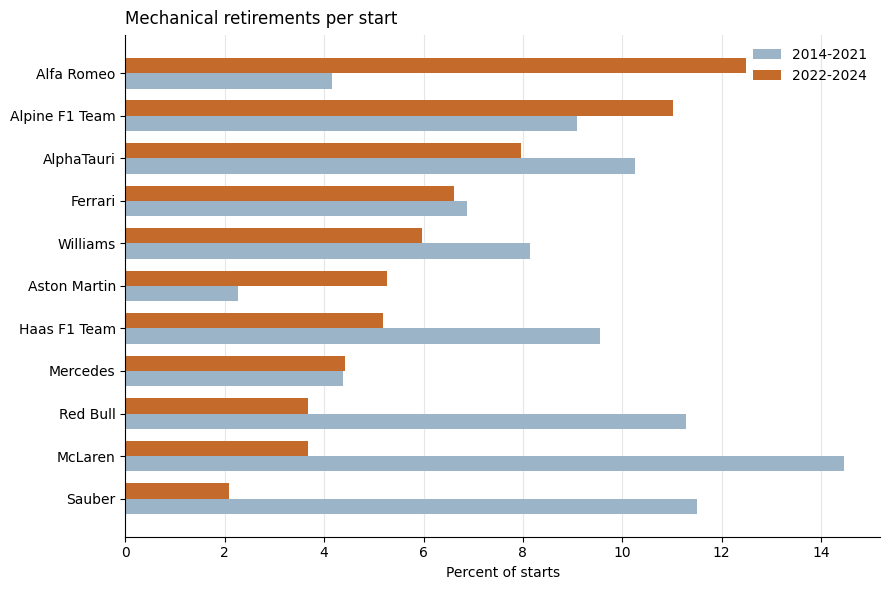

In [25]:
audit = status_audit(result.cleaned["status"])
print(audit["category"].value_counts().to_string())
mechanical = mechanical_retirements(
    result.driver_race, result.cleaned["status"], result.cleaned["constructors"]
)
print(narrate_mechanical(mechanical))
display(mechanical)
save(plot_mechanical(mechanical), "14_mechanical_retirements.png")
audit.to_csv(PATHS["audit"] / "status_categories.csv", index=False)